In [2]:
# 1. Imports, file paths, and experiment configuration (Section 4.2).
# Check the training data checksum to ensure reproducible inputs.
# Set tuning/plotting options and create the output directory.

from pathlib import Path
import time, json, re, warnings, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import PredefinedSplit, cross_validate, RandomizedSearchCV
from sklearn.metrics import make_scorer
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.tree import DecisionTreeRegressor, export_text, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

# Configure reproducibility, input validation, and output locations.
SEED = 0
TRAIN_PATH = Path('nextgen_train_5fold.csv')
EXPECTED_TRAIN_SHA256 = 'df3bea205f57df01beb6685edac92e5e8215a927ac6b419b441cc824b6544fcc'
if not TRAIN_PATH.is_file():
    raise FileNotFoundError(
        f'Training file not found: {TRAIN_PATH.resolve()}. '
        ''
        'Check the file path.'
    )
actual_train_sha256 = hashlib.sha256(TRAIN_PATH.read_bytes()).hexdigest()
if actual_train_sha256 != EXPECTED_TRAIN_SHA256:
    raise ValueError(
        'Training CSV checksum mismatch. '
        f'Expected SHA256 {EXPECTED_TRAIN_SHA256}, got {actual_train_sha256}. '
        'Verify the CSV contents.'
    )
print('Training CSV:', TRAIN_PATH.resolve())
VAL_PATH = Path('nextgen_validation.csv')
KAGGLE_TEST_PATH = Path('nextgen_kaggle_test.csv')
SAMPLE_SUBMISSION_PATH = Path('sample_submission.csv')
RESULT_DIR = Path('PartC_DT_RF_Final_Outputs')
RESULT_DIR.mkdir(parents=True, exist_ok=True)

# Run settings: disable fast mode for full hyperparameter searches.
FAST_MODE = False                 # True: quick structural test, NOT final tuned results
RUN_LOG_TARGET = True             # log1p-target DT/RF, tested independently
RUN_FEATURE_IMPORTANCE = True    # RF log-target only; switch off for fast reruns
RUN_KAGGLE = True                 # export only if official Kaggle CSVs are available
SEARCH_JOBS = 2                  # model search parallelism; each RF search fit uses 1 CPU
PERMUTATION_REPEATS = 5
PLOT_DPI = 220

# Helpers for consistent filenames and saved plots.
def slug(name):
    return re.sub(r'[^a-z0-9]+','_',name.lower()).strip('_')

def save_plot(fig, name):
    path = RESULT_DIR / (name + '.png')
    fig.savefig(path, dpi=PLOT_DPI, bbox_inches='tight', facecolor='white')
    plt.show()
    print('Saved plot:',path)

print('Result directory:',RESULT_DIR.resolve())
print('Experiment: raw-target DT/RF with RMSE and RMSLE tuning; optional log-target variants')


Training CSV: C:\Users\windows\OneDrive - The University of Sydney (Students)\Desktop\QBUS6600 Group ASM\nextgen_train_5fold.csv
Result directory: C:\Users\windows\OneDrive - The University of Sydney (Students)\Desktop\QBUS6600 Group ASM\PartC_DT_RF_Final_Outputs
Experiment: raw-target DT/RF with RMSE and RMSLE tuning; optional log-target variants


In [3]:
# 2. Feature selection and fixed-fold data validation (Section 4.2.1).
# Load the 14 engineered predictors and the 730-day ancillary-revenue target.
# Verify membership IDs, household separation, target values, and fixed CV folds.

selected_features = [
    'Age', 'membership_tenure_days', 'member_role', 'SubLevel1',
    'mosaic_group_clean', 'days_since_last_attendance', 'attendance_180d',
    'revenue_730d', 'recent_revenue_180d', 'sales_transactions_730d',
    'days_since_last_sale', 'spending_category_count', 'fb_spend_730d',
    'booking_count_180d'
]
categorical_features = ['SubLevel1','mosaic_group_clean']
numeric_features = [f for f in selected_features if f not in categorical_features]
target = 'revenue_next_730d'
assert len(selected_features)==14 and len(set(selected_features))==14

# Read the agreed train/validation exports; do not create a new split.
for path in (TRAIN_PATH, VAL_PATH):
    if not path.exists():
        raise FileNotFoundError(f'Missing input: {path}. Do not re-split.')
train_export = pd.read_csv(TRAIN_PATH, float_precision='round_trip',
                           dtype={'HashID':str,'HouseholdID':str})
val_export = pd.read_csv(VAL_PATH, float_precision='round_trip',
                         dtype={'HashID':str,'HouseholdID':str})
required=['HashID','HouseholdID']+selected_features+[target]
assert set(required+['cv_fold']).issubset(train_export.columns), 'Training columns missing'
assert set(required).issubset(val_export.columns), 'Validation columns missing'
assert len(train_export)==9835 and len(val_export)==2437, 'Incorrect shared split sizes'
for df in (train_export,val_export):
    assert df['HashID'].notna().all() and df['HashID'].is_unique
    assert df['HouseholdID'].notna().all()
    for f in numeric_features+[target]:df[f]=pd.to_numeric(df[f],errors='raise')
    for f in categorical_features:
        df[f]=df[f].map(lambda v: str(v) if pd.notna(v) else np.nan)
    assert np.isfinite(df[target]).all() and df[target].ge(0).all()
    assert not np.isinf(df[numeric_features].to_numpy(dtype=float)).any()
    df.reset_index(drop=True, inplace=True)
# Prevent member or household overlap and verify fold integrity.
assert set(train_export.HashID).isdisjoint(val_export.HashID)
assert set(train_export.HouseholdID).isdisjoint(val_export.HouseholdID)
assert train_export.cv_fold.notna().all()
assert (train_export.cv_fold == train_export.cv_fold.astype(int)).all()
train_export['cv_fold']=train_export['cv_fold'].astype(int)
assert sorted(train_export.cv_fold.unique().tolist())==list(range(5))
assert (train_export.groupby('HouseholdID').cv_fold.nunique()==1).all()
fold_balance=train_export.groupby('cv_fold').agg(
    Members=('HashID','size'),Households=('HouseholdID','nunique'),
    Mean_target=(target,'mean'),Zero_pct=(target,lambda y:y.eq(0).mean()*100)
)
expected_members=np.array([1967]*5)
expected_households=np.array([1450,1450,1451,1451,1451])
expected_means=np.array([432.51,462.27,478.21,506.18,498.58])
expected_zero=np.array([34.77,34.67,34.21,32.89,33.86])
if not (np.array_equal(fold_balance.Members.to_numpy(),expected_members)
        and np.array_equal(fold_balance.Households.to_numpy(),expected_households)
        and np.allclose(fold_balance.Mean_target,expected_means,atol=.0051,rtol=0)
        and np.allclose(fold_balance.Zero_pct,expected_zero,atol=.0051,rtol=0)):
    raise ValueError('Fold statistics do not match the expected data. Verify TRAIN_PATH.')
# Reuse the stored fold labels when evaluating every candidate model.
cv=PredefinedSplit(test_fold=train_export.cv_fold.to_numpy())
X_train,y_train=train_export[selected_features].copy(),train_export[target].copy()
X_val,y_val=val_export[selected_features].copy(),val_export[target].copy()
fold_balance.to_csv(RESULT_DIR/'fold_balance.csv')
print('Household CV folds:', X_train.shape, X_val.shape, 'SEED=',SEED)
display(fold_balance.round(3))


Household CV folds: (9835, 14) (2437, 14) SEED= 0


,Members,Households,Mean_target,Zero_pct
cv_fold,,,,
0,1967,1450,432.513,34.774
1,1967,1450,462.273,34.672
2,1967,1451,478.208,34.215
3,1967,1451,506.175,32.893
4,1967,1451,498.578,33.859


In [4]:
# 3. Preprocessing and reusable evaluation functions (Sections 4.2.1–4.2.2).
# Fit imputation, scaling, and encoding within each modelling pipeline.
# Apply consistent non-negative revenue predictions and RMSE/RMSLE scoring.
# Store validation predictions, fold scores, training times, and model summaries.

# Numerical and categorical transformations are fit inside CV folds.
numeric_pipeline=Pipeline([
    ('imputer',SimpleImputer(strategy='median',add_indicator=True)),
    ('scaler',StandardScaler())
])
categorical_pipeline=Pipeline([
    ('imputer',SimpleImputer(strategy='constant',fill_value='Unknown')),
    ('encoder',OneHotEncoder(handle_unknown='ignore',sparse_output=False))
])
preprocessor=ColumnTransformer([
    ('numeric',numeric_pipeline,numeric_features),
    ('categorical',categorical_pipeline,categorical_features)
])
linear_preprocessor=clone(preprocessor)
linear_preprocessor.set_params(categorical__encoder__drop='first')

# Use the same prediction handling and metrics for all regressors.
def prepare_predictions(y_true,y_pred):
    a=np.asarray(y_true,dtype=float).reshape(-1)
    p=np.asarray(y_pred,dtype=float).reshape(-1)
    if a.shape!=p.shape or not np.isfinite(a).all() or not np.isfinite(p).all():
        raise ValueError('Invalid target or predictions; check shapes/NaNs/extreme model outputs')
    if (a<0).any():raise ValueError('Revenue target must be non-negative')
    return a,np.clip(p,0,None)

def evaluate_rmse(y_true,y_pred):
    a,p=prepare_predictions(y_true,y_pred)
    return float(np.sqrt(np.mean((a-p)**2)))

def evaluate_rmsle(y_true,y_pred):
    a,p=prepare_predictions(y_true,y_pred)
    return float(np.sqrt(np.mean((np.log1p(a)-np.log1p(p))**2)))

scoring={
    'RMSE':make_scorer(evaluate_rmse,greater_is_better=False),
    'RMSLE':make_scorer(evaluate_rmsle,greater_is_better=False)
}
# Containers for consistent cross-model comparisons and diagnostics.
result_columns=['Model','Train_RMSE','Train_RMSLE','Val_RMSE','Val_RMSLE',
                'Gap','CV_RMSE_mean','CV_RMSE_SD','CV_RMSLE_mean',
                'CV_RMSLE_SD','Training_time_s','Search_time_s',
                'Target_scale','Selection_metric']
result_rows=[]
fold_rows=[]
param_rows=[]
fitted_models={}
model_templates={}
validation_predictions={}
search_objects={}

# Run fixed-fold CV for a baseline, then fit once on all training members.
def evaluate_fixed_model(name,template,target_scale='raw',selection_metric='Baseline'):
    start_cv=time.perf_counter()
    scores=cross_validate(clone(template),X_train,y_train,cv=cv,scoring=scoring,n_jobs=1,error_score='raise')
    cv_time=time.perf_counter()-start_cv
    fitted=clone(template)
    start=time.perf_counter();fitted.fit(X_train,y_train);fit_time=time.perf_counter()-start
    return record_model(name,fitted,-scores['test_RMSE'],-scores['test_RMSLE'],
                        fit_time,cv_time,target_scale,selection_metric)

# Store model-level metrics and member-level holdout predictions.
def record_model(name, fitted, cv_rmse, cv_rmsle, fit_time, search_time, target_scale, selection_metric):
    cv_rmse=np.asarray(cv_rmse,dtype=float)
    cv_rmsle=np.asarray(cv_rmsle,dtype=float)
    pred_tr=fitted.predict(X_train)
    pred_val=fitted.predict(X_val)
    tr_rmse=evaluate_rmse(y_train,pred_tr)
    v_rmse=evaluate_rmse(y_val,pred_val)
    row={'Model':name,'Train_RMSE':tr_rmse,'Train_RMSLE':evaluate_rmsle(y_train,pred_tr),
         'Val_RMSE':v_rmse,'Val_RMSLE':evaluate_rmsle(y_val,pred_val),
         'Gap':v_rmse-tr_rmse,'CV_RMSE_mean':cv_rmse.mean(),
         'CV_RMSE_SD':cv_rmse.std(ddof=1), 'CV_RMSLE_mean':cv_rmsle.mean(),
         'CV_RMSLE_SD':cv_rmsle.std(ddof=1),'Training_time_s':fit_time,
         'Search_time_s':search_time,'Target_scale':target_scale,
         'Selection_metric':selection_metric}
    result_rows.append(row)
    for fold in range(5):
        fold_rows.append({'Model':name,'cv_fold':fold,'RMSE':cv_rmse[fold], 'RMSLE':cv_rmsle[fold]})
    fitted_models[name]=fitted
    validation_predictions[name]=np.clip(np.asarray(pred_val,dtype=float),0,None)
    x=val_export[['HashID','HouseholdID',target]].copy()
    x['Prediction']=validation_predictions[name]
    x['Residual_Actual_minus_Pred']=x[target]-x['Prediction']
    x['Squared_Error']=x['Residual_Actual_minus_Pred']**2
    x.to_csv(RESULT_DIR/(slug(name)+'_validation_predictions.csv'),index=False)
    print(f'{name:27} Val RMSE={row["Val_RMSE"]:,.3f} | Val RMSLE={row["Val_RMSLE"]:.4f} | CV RMSLE={row["CV_RMSLE_mean"]:.4f}±{row["CV_RMSLE_SD"]:.4f}',flush=True)
    return row

print('Shared metric definitions:',list(scoring))


Shared metric definitions: ['RMSE', 'RMSLE']


In [5]:
# 4. Benchmark regressors (Section 4.2.2).
# Evaluate mean, median, OLS, and log-target OLS with the same fixed five-fold CV.
# Verify the OLS benchmark against the expected reference metrics.

def make_ols_pipeline():
    return Pipeline([('preprocessor',clone(linear_preprocessor)),('model',LinearRegression())])
baseline_models={
    'Mean baseline':DummyRegressor(strategy='mean'),
    'Median baseline':DummyRegressor(strategy='median'),
    'OLS':make_ols_pipeline(),
    'Log-target OLS':TransformedTargetRegressor(
        regressor=make_ols_pipeline(),func=np.log1p,inverse_func=np.expm1)
}
# Fit and evaluate benchmarks using the shared evaluation function.
for name,template in baseline_models.items():
    model_templates[name]=clone(template)
    print('Baseline:',name,flush=True)
    evaluate_fixed_model(name,template,target_scale='log1p' if 'Log-target' in name else 'raw')

# Detect unexpected changes in the reference OLS results.
ols=next(r for r in result_rows if r['Model']=='OLS')
assert abs(ols['Val_RMSE']-788.821064352531)<0.1, 'OLS holdout differs from original benchmark.'
assert abs(ols['CV_RMSE_mean']-796.0047858296701)<0.01, 'OLS CV RMSE mean differs from group final.'
assert abs(ols['CV_RMSE_SD']-37.47371169146262)<0.01, 'OLS CV RMSE SD differs from group final.'
assert abs(ols['CV_RMSLE_mean']-2.76964901091731)<0.005, 'OLS CV RMSLE mean differs from group final.'
assert abs(ols['CV_RMSLE_SD']-0.01665214379593822)<0.005, 'OLS CV RMSLE SD differs from group final.'
print('OLS benchmark verified.')


Baseline: Mean baseline
Mean baseline               Val RMSE=1,194.784 | Val RMSLE=4.0012 | CV RMSLE=3.9479±0.0502
Baseline: Median baseline
Median baseline             Val RMSE=1,263.897 | Val RMSLE=2.9374 | CV RMSLE=2.9219±0.0095
Baseline: OLS
OLS                         Val RMSE=788.821 | Val RMSLE=2.8008 | CV RMSLE=2.7696±0.0167
Baseline: Log-target OLS
Log-target OLS              Val RMSE=7,657,499.287 | Val RMSLE=1.9860 | CV RMSLE=2.0200±0.0297
OLS benchmark verified.


In [6]:
# 5. Untuned Decision Tree and Random Forest benchmarks (Section 4.2.2).
# Compare train/validation errors before hyperparameter tuning to assess overfitting.

raw_models={
    'DT baseline':Pipeline([
        ('preprocessor',clone(preprocessor)),
        ('model',DecisionTreeRegressor(random_state=SEED))]),
    'RF baseline':Pipeline([
        ('preprocessor',clone(preprocessor)),
        ('model',RandomForestRegressor(n_estimators=200,random_state=SEED,n_jobs=-1))])
}
# Evaluate default tree and ensemble complexity before tuning.
for name,template in raw_models.items():
    print('Raw baseline:',name,flush=True)
    model_templates[name]=clone(template)
    evaluate_fixed_model(name,template)


Raw baseline: DT baseline
DT baseline                 Val RMSE=1,138.113 | Val RMSLE=2.7071 | CV RMSLE=2.7173±0.0384
Raw baseline: RF baseline
RF baseline                 Val RMSE=817.413 | Val RMSLE=2.7869 | CV RMSLE=2.7666±0.0416


In [7]:
# 6. Raw-target DT/RF hyperparameter tuning (Sections 4.2.1–4.2.2).
# Search DT complexity and RF ensemble settings using RandomizedSearchCV.
# Tune each algorithm separately for RMSE and RMSLE and retain all fold scores.

dt_space={
    'model__max_depth':[3,5,8,12,20,None],
    'model__min_samples_split':[2,10,30,60],
    'model__min_samples_leaf':[1,5,10,20,50]
}
rf_space={
    'model__n_estimators':[200,400],
    'model__max_depth':[8,15,25,None],
    'model__min_samples_leaf':[1,3,5,10,20],
    'model__max_features':['sqrt',0.5,0.8,1.0]
}

# Search one specification, retain selected CV folds, and save the best estimator.
def tune_and_record(name,template,space,metric,n_iter,target_scale='raw'):
    fit_template=clone(template)
    if name.startswith('RF'):
        if target_scale=='log1p':fit_template.set_params(regressor__model__n_jobs=1)
        else:fit_template.set_params(model__n_jobs=1)
    search=RandomizedSearchCV(
        estimator=fit_template,param_distributions=space,n_iter=n_iter,
        scoring=scoring,refit=metric,cv=cv,random_state=SEED,
        n_jobs=SEARCH_JOBS,verbose=1,error_score='raise',return_train_score=False)
    print('\nSearching',name,'metric=',metric,'n_iter=',n_iter,flush=True)
    t0=time.perf_counter();search.fit(X_train,y_train);elapsed=time.perf_counter()-t0
    idx=search.best_index_
    fold_rmse=-np.asarray([search.cv_results_[f'split{i}_test_RMSE'][idx] for i in range(5)])
    fold_rmsle=-np.asarray([search.cv_results_[f'split{i}_test_RMSLE'][idx] for i in range(5)])
    fitted=search.best_estimator_ # refitted by RandomizedSearchCV on entire X_train
    fitted_models[name]=fitted
    model_templates[name]=clone(fitted)
    search_objects[name]=search
    row=record_model(name,fitted,fold_rmse,fold_rmsle,search.refit_time_,elapsed,target_scale,metric)
    param_rows.append({'Model':name,'Selection_metric':metric,
                       'Best_parameters':json.dumps(search.best_params_,sort_keys=True,default=str),
                       'Best_selection_CV_score':-search.best_score_,
                       'Search_iterations':n_iter,'Search_time_s':elapsed})
    pd.DataFrame(search.cv_results_).to_csv(RESULT_DIR/(slug(name)+'_search.csv'),index=False)
    print('Best hyperparameters:',search.best_params_)
    return row

# Build four raw-revenue candidates: DT/RF × RMSE/RMSLE tuning.
for metric in ['RMSE','RMSLE']:
    dt_name=f'DT {metric} tuned'
    rf_name=f'RF {metric} tuned'
    tune_and_record(dt_name,raw_models['DT baseline'],dt_space,metric,
                    n_iter=3 if FAST_MODE else 30)
    tune_and_record(rf_name,raw_models['RF baseline'],rf_space,metric,
                    n_iter=2 if FAST_MODE else 20)



Searching DT RMSE tuned metric= RMSE n_iter= 30
Fitting 5 folds for each of 30 candidates, totalling 150 fits
DT RMSE tuned               Val RMSE=776.522 | Val RMSLE=2.8215 | CV RMSLE=2.8018±0.0534
Best hyperparameters: {'model__min_samples_split': 60, 'model__min_samples_leaf': 50, 'model__max_depth': 8}

Searching RF RMSE tuned metric= RMSE n_iter= 20
Fitting 5 folds for each of 20 candidates, totalling 100 fits
RF RMSE tuned               Val RMSE=783.544 | Val RMSLE=2.7992 | CV RMSLE=2.7726±0.0324
Best hyperparameters: {'model__n_estimators': 200, 'model__min_samples_leaf': 10, 'model__max_features': 0.8, 'model__max_depth': None}

Searching DT RMSLE tuned metric= RMSLE n_iter= 30
Fitting 5 folds for each of 30 candidates, totalling 150 fits
DT RMSLE tuned              Val RMSE=889.784 | Val RMSLE=2.5966 | CV RMSLE=2.5372±0.0607
Best hyperparameters: {'model__min_samples_split': 10, 'model__min_samples_leaf': 10, 'model__max_depth': 20}

Searching RF RMSLE tuned metric= RMSLE n_i

In [8]:
# 7. Log-target DT/RF hyperparameter tuning (Sections 4.2.1–4.2.2).
# Fit models to log(1 + revenue), convert predictions back to AUD,
# and select the best DT and RF settings by household-grouped CV RMSLE.

if RUN_LOG_TARGET:
    def make_log_target_tree_pipeline(regressor):
        return TransformedTargetRegressor(
            regressor=Pipeline([
                ('preprocessor',clone(preprocessor)),
                ('model',regressor)]),
            func=np.log1p,inverse_func=np.expm1,check_inverse=True)
    dt_log=make_log_target_tree_pipeline(DecisionTreeRegressor(random_state=SEED))
    rf_log=make_log_target_tree_pipeline(RandomForestRegressor(random_state=SEED,n_jobs=1))
    # Explore tree complexity after transforming the training target.
    dt_log_space={
        'regressor__model__max_depth':[2,3,4,5,6,8,12,16,None],
        'regressor__model__min_samples_split':[2,10,30,60,120],
        'regressor__model__min_samples_leaf':[5,10,20,40,80,150]
    }
    rf_log_space={
        'regressor__model__n_estimators':[200,400],
        'regressor__model__max_depth':[5,8,12,18,None],
        'regressor__model__min_samples_split':[2,10,30],
        'regressor__model__min_samples_leaf':[2,5,10,20,40,80],
        'regressor__model__max_features':['sqrt',0.5,0.8,1.0]
    }
    # Compare two additional models: log-target DT and log-target RF.
    tune_and_record('DT log-target RMSLE tuned',dt_log,dt_log_space,'RMSLE',
                    n_iter=4 if FAST_MODE else 35,target_scale='log1p')
    tune_and_record('RF log-target RMSLE tuned',rf_log,rf_log_space,'RMSLE',
                    n_iter=2 if FAST_MODE else 25,target_scale='log1p')
else:
    print('Log-target experiments explicitly skipped. Raw RMSE/RMSLE DT/RF still complete.')



Searching DT log-target RMSLE tuned metric= RMSLE n_iter= 35
Fitting 5 folds for each of 35 candidates, totalling 175 fits
DT log-target RMSLE tuned   Val RMSE=939.476 | Val RMSLE=1.8823 | CV RMSLE=1.9573±0.0376
Best hyperparameters: {'regressor__model__min_samples_split': 120, 'regressor__model__min_samples_leaf': 80, 'regressor__model__max_depth': None}

Searching RF log-target RMSLE tuned metric= RMSLE n_iter= 25
Fitting 5 folds for each of 25 candidates, totalling 125 fits
RF log-target RMSLE tuned   Val RMSE=987.658 | Val RMSLE=1.8284 | CV RMSLE=1.8882±0.0286
Best hyperparameters: {'regressor__model__n_estimators': 200, 'regressor__model__min_samples_split': 10, 'regressor__model__min_samples_leaf': 10, 'regressor__model__max_features': 'sqrt', 'regressor__model__max_depth': None}


In [9]:
# 8. Save model comparisons and supporting performance tables (Section 4.2.2).
# Export train/validation metrics, CV variability, and selected hyperparameters.
# Values are calculated from this run; no report figures are hard-coded.

comparison_table=pd.DataFrame(result_rows,columns=result_columns)
cv_fold_results=pd.DataFrame(fold_rows)
best_params_table=pd.DataFrame(param_rows)
comparison_table.to_csv(RESULT_DIR/'part_c_model_comparison_full.csv',index=False)
cv_fold_results.to_csv(RESULT_DIR/'part_c_cv_folds.csv',index=False)
best_params_table.to_csv(RESULT_DIR/'part_c_best_hyperparameters.csv',index=False)

# Summarise the principal model-selection metrics for reporting.
report_main=comparison_table[['Model','Val_RMSE','Val_RMSLE','CV_RMSLE_mean','CV_RMSLE_SD']].copy()
report_main.columns=['Model','Validation RMSE','Validation RMSLE','CV RMSLE Mean','CV RMSLE SD']
report_main['CV RMSLE Mean ± SD']=report_main.apply(
    lambda r:f'{r["CV RMSLE Mean"]:.4f} ± {r["CV RMSLE SD"]:.4f}',axis=1)
report_main=report_main[['Model','Validation RMSE','Validation RMSLE','CV RMSLE Mean ± SD']]
print('\n=== REPORT MAIN MODEL COMPARISON ===')
display(report_main.round(3))
report_main.to_csv(RESULT_DIR/'REPORT_model_comparison.csv',index=False)

# Export supporting train/validation, CV, and tuning details.
appendix_a1=comparison_table[['Model','Train_RMSE','Train_RMSLE','Val_RMSE','Val_RMSLE','Gap']].copy()
print('\n=== APPENDIX A1: TRAIN AND VALIDATION ===')
display(appendix_a1.round(3))
appendix_a1.to_csv(RESULT_DIR/'APPENDIX_A1_train_validation.csv',index=False)

appendix_a2=comparison_table[['Model','CV_RMSE_mean','CV_RMSE_SD','CV_RMSLE_mean',
                              'CV_RMSLE_SD','Training_time_s','Search_time_s']].copy()
print('\n=== APPENDIX A2: FIVE-FOLD CV AND COMPUTATION ===')
display(appendix_a2.round(3))
appendix_a2.to_csv(RESULT_DIR/'APPENDIX_A2_cv_and_time.csv',index=False)

print('\n=== APPENDIX A3: BEST PARAMS AND SEARCH METRIC ===')
display(best_params_table)
best_params_table.to_csv(RESULT_DIR/'APPENDIX_A3_tuning_specs.csv',index=False)

# Keep a separate DT/RF-only comparison for the model-building section.
tree_comparison=comparison_table.loc[comparison_table.Model.str.match(r'^(DT|RF) ')].copy()
tree_comparison.to_csv(RESULT_DIR/'REPORT_dt_rf_only.csv',index=False)



=== REPORT MAIN MODEL COMPARISON ===


,Model,Validation RMSE,Validation RMSLE,CV RMSLE Mean ± SD
0,Mean baseline,1194.784,4.001,3.9479 ± 0.0502
1,Median baseline,1263.897,2.937,2.9219 ± 0.0095
2,OLS,788.821,2.801,2.7696 ± 0.0167
3,Log-target OLS,7657499.287,1.986,2.0200 ± 0.0297
4,DT baseline,1138.113,2.707,2.7173 ± 0.0384
5,RF baseline,817.413,2.787,2.7666 ± 0.0416
6,DT RMSE tuned,776.522,2.821,2.8018 ± 0.0534
7,RF RMSE tuned,783.544,2.799,2.7726 ± 0.0324
8,DT RMSLE tuned,889.784,2.597,2.5372 ± 0.0607
9,RF RMSLE tuned,802.629,2.789,2.7562 ± 0.0338



=== APPENDIX A1: TRAIN AND VALIDATION ===


,Model,Train_RMSE,Train_RMSLE,Val_RMSE,Val_RMSLE,Gap
0,Mean baseline,1189.675,3.948,1194.784,4.001,5.108
1,Median baseline,1264.305,2.921,1263.897,2.937,-0.409
2,OLS,790.351,2.754,788.821,2.801,-1.530
3,Log-target OLS,105239.599,2.011,7657499.287,1.986,7552259.688
4,DT baseline,7.971,0.064,1138.113,2.707,1130.142
5,RF baseline,297.839,2.051,817.413,2.787,519.574
6,DT RMSE tuned,785.547,2.756,776.522,2.821,-9.025
7,RF RMSE tuned,671.811,2.627,783.544,2.799,111.733
8,DT RMSLE tuned,669.844,2.164,889.784,2.597,219.940
9,RF RMSLE tuned,482.053,2.384,802.629,2.789,320.576



=== APPENDIX A2: FIVE-FOLD CV AND COMPUTATION ===


,Model,CV_RMSE_mean,CV_RMSE_SD,CV_RMSLE_mean,CV_RMSLE_SD,Training_time_s,Search_time_s
0,Mean baseline,1188.159,70.704,3.948,0.050,0.001,0.027
1,Median baseline,1262.572,74.442,2.922,0.010,0.001,0.063
2,OLS,796.005,37.474,2.770,0.017,0.123,0.723
3,Log-target OLS,96009.179,115043.012,2.020,0.030,0.060,0.410
4,DT baseline,1139.770,65.136,2.717,0.038,0.321,1.568
5,RF baseline,819.191,42.573,2.767,0.042,11.509,45.365
6,DT RMSE tuned,846.749,53.869,2.802,0.053,0.135,36.699
7,RF RMSE tuned,804.761,48.031,2.773,0.032,21.459,2128.868
8,DT RMSLE tuned,896.158,35.221,2.537,0.061,0.475,30.844
9,RF RMSLE tuned,811.544,43.360,2.756,0.034,63.571,1878.209



=== APPENDIX A3: BEST PARAMS AND SEARCH METRIC ===


,Model,Selection_metric,Best_parameters,Best_selection_CV_score,Search_iterations,Search_time_s
0,DT RMSE tuned,RMSE,"{""model__max_depth"": 8, ""model__min_samples_le...",846.749348,30,36.699494
1,RF RMSE tuned,RMSE,"{""model__max_depth"": null, ""model__max_feature...",804.761398,20,2128.867595
2,DT RMSLE tuned,RMSLE,"{""model__max_depth"": 20, ""model__min_samples_l...",2.537200,30,30.844464
3,RF RMSLE tuned,RMSLE,"{""model__max_depth"": 25, ""model__max_features""...",2.756189,20,1878.209055
4,DT log-target RMSLE tuned,RMSLE,"{""regressor__model__max_depth"": null, ""regress...",1.957312,35,26.288654
5,RF log-target RMSLE tuned,RMSLE,"{""regressor__model__max_depth"": null, ""regress...",1.888194,25,970.528675


In [11]:
# 9. Confirm which models have stored holdout predictions.
# Check availability before running the following prediction diagnostics.

print(list(validation_predictions.keys()))

['Mean baseline', 'Median baseline', 'OLS', 'Log-target OLS', 'DT baseline', 'RF baseline', 'DT RMSE tuned', 'RF RMSE tuned', 'DT RMSLE tuned', 'RF RMSLE tuned', 'DT log-target RMSLE tuned', 'RF log-target RMSLE tuned']


In [12]:
# 10. Holdout error analysis across realised future-revenue segments (Section 4.2.3).
# Examine zero spenders and high-value tails without using future revenue as a predictor.
# Quantify how much squared error is concentrated in the worst 1% and 5% of predictions.

actual=y_val.to_numpy(dtype=float)
p90,p99=np.quantile(y_train.to_numpy(dtype=float),[.90,.99])
error_rows=[]; concentration_rows=[]
plot_order = list(validation_predictions.keys())
# Generate diagnostic groups from observed holdout outcomes only.
for name in plot_order:
    pred=np.asarray(validation_predictions[name],dtype=float)
    err=actual-pred; sq=err**2; total=sq.sum()
    for label,mask in [('Zero',actual==0),('Positive to P90',(actual>0)&(actual<=p90)),
                       ('P90 to P99',(actual>p90)&(actual<=p99)),('Above P99',actual>p99)]:
        if mask.sum()==0: continue
        error_rows.append({'Model':name,'Segment':label,'Members':int(mask.sum()),
          'Mean_actual':actual[mask].mean(),'Mean_predicted':pred[mask].mean(),
          'RMSE':evaluate_rmse(actual[mask],pred[mask]),
          'RMSLE':evaluate_rmsle(actual[mask],pred[mask]),
          'SSE_share_pct':100*sq[mask].sum()/total})
    concentration_rows.append({'Model':name,'Worst_1pct_SSE_share':100*np.sort(sq)[-int(np.ceil(len(sq)*.01)):].sum()/total,
                               'Worst_5pct_SSE_share':100*np.sort(sq)[-int(np.ceil(len(sq)*.05)):].sum()/total})
# Export segment-level errors and concentration statistics.
errors=pd.DataFrame(error_rows); concentration=pd.DataFrame(concentration_rows)
errors.to_csv(RESULT_DIR/'APPENDIX_error_by_realised_segment.csv',index=False)
concentration.to_csv(RESULT_DIR/'APPENDIX_error_concentration.csv',index=False)
print('Selected error concentration:')
display(concentration[concentration.Model.isin(['RF RMSE tuned','RF log-target RMSLE tuned'])].round(2))


Selected error concentration:


,Model,Worst_1pct_SSE_share,Worst_5pct_SSE_share
7,RF RMSE tuned,56.09,85.44
11,RF log-target RMSLE tuned,65.89,91.37


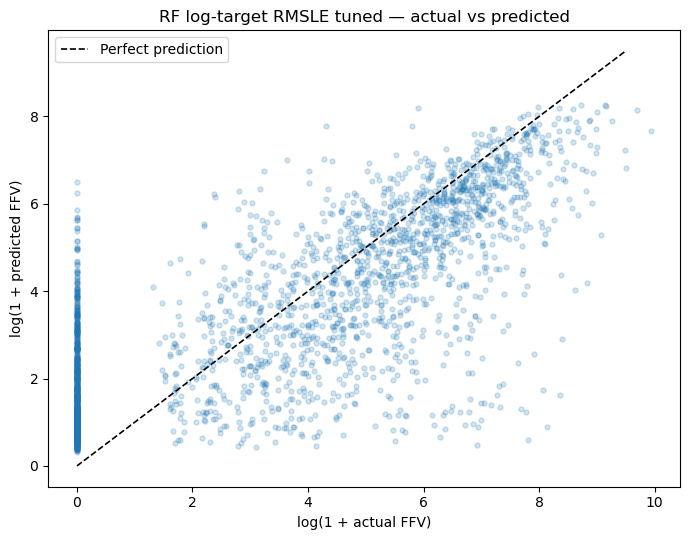

Saved plot: PartC_DT_RF_Final_Outputs\FIG_RF_logtarget_actual_predicted.png


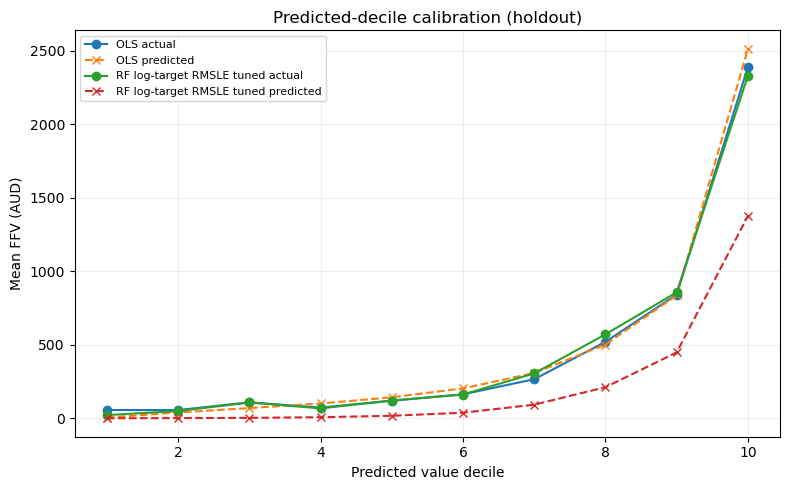

Saved plot: PartC_DT_RF_Final_Outputs\FIG_predicted_decile_calibration.png


In [13]:
# 11. Prediction accuracy and calibration figures (Section 4.2.3).
# Plot the log-target RF holdout predictions against realised revenue.
# Compare actual versus predicted mean revenue by predicted decile for RF and OLS.

name='RF log-target RMSLE tuned'
assert name in validation_predictions
pred=np.asarray(validation_predictions[name],dtype=float)
a=np.log1p(actual);p=np.log1p(pred)
fig,ax=plt.subplots(figsize=(7,5.5));ax.scatter(a,p,s=13,alpha=.20)
lim=max(np.quantile(a,.999),np.quantile(p,.999))
ax.plot([0,lim],[0,lim],'k--',lw=1.2,label='Perfect prediction')
ax.set(xlabel='log(1 + actual FFV)',ylabel='log(1 + predicted FFV)',title='RF log-target RMSLE tuned — actual vs predicted')
ax.legend();fig.tight_layout();save_plot(fig,'FIG_RF_logtarget_actual_predicted')

# Group members by predicted (not actual) revenue decile for calibration checks.
calibration_rows=[]
for label in ['OLS',name]:
    pp=np.asarray(validation_predictions[label],dtype=float)
    dec=pd.qcut(pd.Series(pp).rank(method='first'),10,labels=False)+1
    z=pd.DataFrame({'Decile':dec,'Actual':actual,'Predicted':pp})
    g=z.groupby('Decile',as_index=False).agg(Actual_mean=('Actual','mean'),Predicted_mean=('Predicted','mean'))
    g['Model']=label;calibration_rows.append(g)
calibration=pd.concat(calibration_rows,ignore_index=True)
calibration.to_csv(RESULT_DIR/'FIG_DATA_predicted_decile_calibration.csv',index=False)
fig,ax=plt.subplots(figsize=(8,5))
for label in ['OLS',name]:
    g=calibration[calibration.Model.eq(label)]
    ax.plot(g.Decile,g.Actual_mean,marker='o',label=f'{label} actual')
    ax.plot(g.Decile,g.Predicted_mean,marker='x',ls='--',label=f'{label} predicted')
ax.set(xlabel='Predicted value decile',ylabel='Mean FFV (AUD)',title='Predicted-decile calibration (holdout)')
ax.legend(fontsize=8);ax.grid(alpha=.2);fig.tight_layout();save_plot(fig,'FIG_predicted_decile_calibration')


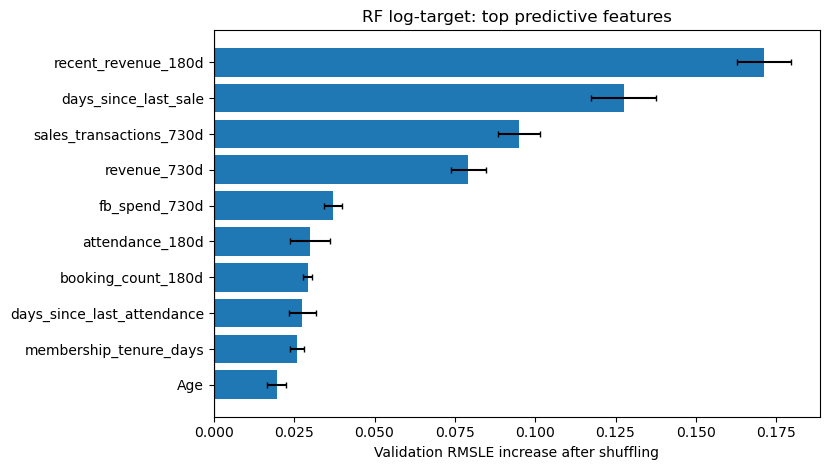

Saved plot: PartC_DT_RF_Final_Outputs\FIG_RF_logtarget_permutation_importance.png


,Feature,Increase_in_RMSLE,SD
8,recent_revenue_180d,0.1713,0.0084
10,days_since_last_sale,0.1275,0.0101
9,sales_transactions_730d,0.0950,0.0064
7,revenue_730d,0.0792,0.0054
12,fb_spend_730d,0.0372,0.0028
6,attendance_180d,0.0299,0.0063
13,booking_count_180d,0.0292,0.0015
5,days_since_last_attendance,0.0276,0.0041
1,membership_tenure_days,0.0258,0.0022
0,Age,0.0195,0.0029


In [14]:
# 12. RF permutation feature importance (Section 4.2.3).
# Measure the increase in holdout RMSLE after shuffling each input feature.
# Export ranked predictor importance and the report figure.

if RUN_FEATURE_IMPORTANCE:
    name='RF log-target RMSLE tuned'
    perm=permutation_importance(fitted_models[name],X_val,y_val,
        scoring=scoring['RMSLE'],n_repeats=PERMUTATION_REPEATS,random_state=SEED,n_jobs=1)
    importance=pd.DataFrame({'Feature':selected_features,'Increase_in_RMSLE':perm.importances_mean,'SD':perm.importances_std})
    importance=importance.sort_values('Increase_in_RMSLE',ascending=False)
    importance.to_csv(RESULT_DIR/'APPENDIX_RF_logtarget_importance.csv',index=False)
    # Plot the ten features with the greatest mean impact on validation RMSLE.
    plot=importance.head(10).iloc[::-1]
    fig,ax=plt.subplots(figsize=(8.4,4.8))
    ax.barh(plot.Feature,plot.Increase_in_RMSLE,xerr=plot.SD,capsize=2)
    ax.axvline(0,color='black',lw=.8)
    ax.set(xlabel='Validation RMSLE increase after shuffling',title='RF log-target: top predictive features')
    fig.tight_layout();save_plot(fig,'FIG_RF_logtarget_permutation_importance')
    display(importance.head(10).round(4))
else:
    print('RF permutation importance skipped (existing report figure may be used).')


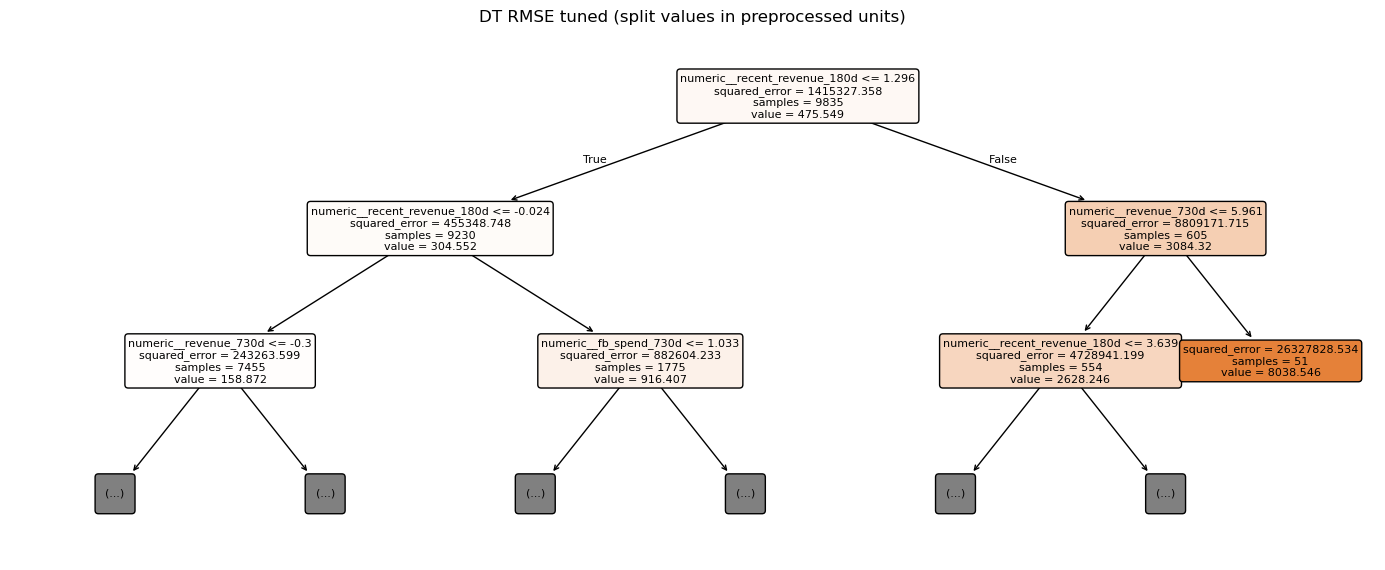

Saved plot: PartC_DT_RF_Final_Outputs\APPENDIX_DT_RMSE_shallow_tree.png


In [15]:
# 13. Decision Tree interpretation (Section 4.2.3).
# Export human-readable split rules and a shallow tree visualization.
# Split thresholds are on the preprocessed feature scale, not always AUD.

def unwrap_tree_pipeline(fitted):
    pipe=fitted.regressor_ if isinstance(fitted,TransformedTargetRegressor) else fitted
    return pipe,pipe.named_steps['preprocessor'],pipe.named_steps['model']
# Use one representative tuned tree to illustrate interpretable upper splits.
name='DT RMSE tuned'
_,prep,tree=unwrap_tree_pipeline(fitted_models[name])
feature_names=list(prep.get_feature_names_out())
(RESULT_DIR/'APPENDIX_DT_RMSE_rules.txt').write_text(
    export_text(tree,feature_names=feature_names,max_depth=3),encoding='utf-8')
fig,ax=plt.subplots(figsize=(14,5.8))
plot_tree(tree,feature_names=feature_names,max_depth=2,filled=True,rounded=True,fontsize=8,ax=ax)
ax.set_title('DT RMSE tuned (split values in preprocessed units)')
fig.tight_layout();save_plot(fig,'APPENDIX_DT_RMSE_shallow_tree')


In [16]:
# 14. Final Kaggle prediction exports (Section 4.2.2).
# Align test members to the official sample-submission order.
# Refit selected model specifications on all labelled members and export predictions.
# This step refits models but does not repeat the hyperparameter searches.

if RUN_KAGGLE and KAGGLE_TEST_PATH.is_file() and SAMPLE_SUBMISSION_PATH.is_file():
    test=pd.read_csv(KAGGLE_TEST_PATH,dtype={'HashID':str},low_memory=False)
    sample=pd.read_csv(SAMPLE_SUBMISSION_PATH,dtype={'HashID':str})
    if not {'HashID',target}.issubset(sample.columns):
        raise ValueError('Official sample must have HashID and '+target)
    if not set(['HashID']+selected_features).issubset(test.columns):
        raise ValueError('Kaggle test missing original selected features')
    if len(test)!=1350 or len(sample)!=1350 or not sample.HashID.is_unique or not test.HashID.is_unique:
        raise ValueError('Kaggle file sizes or HashIDs are invalid')
    if sample.HashID.isna().any() or test.HashID.isna().any():raise ValueError('Missing HashIDs')
    if set(sample.HashID)!=set(test.HashID):raise ValueError('Kaggle ID sets differ')
    test_aligned=sample[['HashID']].merge(test[['HashID']+selected_features],
              on='HashID',how='left',validate='one_to_one',sort=False)
    assert test_aligned.HashID.tolist()==sample.HashID.tolist()
    for f in numeric_features:test_aligned[f]=pd.to_numeric(test_aligned[f],errors='raise')
    for f in categorical_features:
        test_aligned[f]=test_aligned[f].map(lambda v:str(v) if pd.notna(v) else np.nan)
    assert not np.isinf(test_aligned[numeric_features].to_numpy(dtype=float)).any()
    # Train the final submission estimator on every labelled training member.
    full_labeled=pd.concat([train_export,val_export],ignore_index=True)
    assert len(full_labeled)==12272 and full_labeled.HashID.is_unique
    assert set(full_labeled.HashID).isdisjoint(test_aligned.HashID)
    submission_rows=[]
    # Generate one sample-aligned Kaggle CSV per candidate specification.
    for name in [x for x in plot_order if x != 'OLS']:
        estimator=clone(model_templates[name])
        print('Kaggle refit:',name,flush=True)
        t0=time.perf_counter()
        estimator.fit(full_labeled[selected_features],full_labeled[target])
        elapsed=time.perf_counter()-t0
        raw=np.asarray(estimator.predict(test_aligned[selected_features]),dtype=float)
        if raw.shape!=(1350,) or not np.isfinite(raw).all():raise ValueError('Invalid Kaggle predictions: '+name)
        preds=np.clip(raw,0,None)
        output=sample[['HashID']].copy()
        output[target]=preds
        path=RESULT_DIR/('kaggle_submission_'+slug(name)+'.csv')
        output.to_csv(path,index=False)
        submission_rows.append({'Model':name,'File':path.name,'Members':len(output),
                                'Clipped_negative':int(np.sum(raw<0)),
                                'Refit_time_s':elapsed})
        print('Exported:',path,'original label rows:',len(full_labeled))
    kaggle_manifest=pd.DataFrame(submission_rows)
    display(kaggle_manifest)
    kaggle_manifest.to_csv(RESULT_DIR/'KAGGLE_submission_manifest.csv',index=False)
else:
    print('Kaggle export skipped; both nextgen_kaggle_test.csv and sample_submission.csv required.')


Kaggle refit: Mean baseline
Exported: PartC_DT_RF_Final_Outputs\kaggle_submission_mean_baseline.csv original label rows: 12272
Kaggle refit: Median baseline
Exported: PartC_DT_RF_Final_Outputs\kaggle_submission_median_baseline.csv original label rows: 12272
Kaggle refit: Log-target OLS
Exported: PartC_DT_RF_Final_Outputs\kaggle_submission_log_target_ols.csv original label rows: 12272
Kaggle refit: DT baseline
Exported: PartC_DT_RF_Final_Outputs\kaggle_submission_dt_baseline.csv original label rows: 12272
Kaggle refit: RF baseline
Exported: PartC_DT_RF_Final_Outputs\kaggle_submission_rf_baseline.csv original label rows: 12272
Kaggle refit: DT RMSE tuned
Exported: PartC_DT_RF_Final_Outputs\kaggle_submission_dt_rmse_tuned.csv original label rows: 12272
Kaggle refit: RF RMSE tuned
Exported: PartC_DT_RF_Final_Outputs\kaggle_submission_rf_rmse_tuned.csv original label rows: 12272
Kaggle refit: DT RMSLE tuned
Exported: PartC_DT_RF_Final_Outputs\kaggle_submission_dt_rmsle_tuned.csv original la

,Model,File,Members,Clipped_negative,Refit_time_s
0,Mean baseline,kaggle_submission_mean_baseline.csv,1350,0,0.008223
1,Median baseline,kaggle_submission_median_baseline.csv,1350,0,0.008284
2,Log-target OLS,kaggle_submission_log_target_ols.csv,1350,14,0.267429
3,DT baseline,kaggle_submission_dt_baseline.csv,1350,0,0.812492
4,RF baseline,kaggle_submission_rf_baseline.csv,1350,0,23.780726
5,DT RMSE tuned,kaggle_submission_dt_rmse_tuned.csv,1350,0,0.401444
6,RF RMSE tuned,kaggle_submission_rf_rmse_tuned.csv,1350,0,57.541438
7,DT RMSLE tuned,kaggle_submission_dt_rmsle_tuned.csv,1350,0,0.722394
8,RF RMSLE tuned,kaggle_submission_rf_rmsle_tuned.csv,1350,0,86.182303
9,DT log-target RMSLE tuned,kaggle_submission_dt_log_target_rmsle_tuned.csv,1350,0,0.396689


In [17]:
# 15. Additional-model setup (Section 4.2.4; exploratory appendix).
# Reuse the existing features, fixed folds, and saved DT/RF comparison results.
# Create a separate output folder for Tweedie and Historical P80 experiments.

from pathlib import Path
import time
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, PredefinedSplit
from sklearn.linear_model import TweedieRegressor, LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

EXTRA_DIR = Path(RESULT_DIR if 'RESULT_DIR' in globals() else 'PartC_DT_RF_Final_Outputs') / 'additional_models'
EXTRA_DIR.mkdir(parents=True, exist_ok=True)
if 'train_export' not in globals() or 'val_export' not in globals():
    train_export = pd.read_csv('nextgen_train_5fold.csv', dtype={'HashID':str, 'HouseholdID':str}, float_precision='round_trip')
    val_export = pd.read_csv('nextgen_validation.csv', dtype={'HashID':str, 'HouseholdID':str}, float_precision='round_trip')
if 'selected_features' not in globals():
    selected_features = ['Age','membership_tenure_days','member_role','SubLevel1','mosaic_group_clean',
        'days_since_last_attendance','attendance_180d','revenue_730d','recent_revenue_180d',
        'sales_transactions_730d','days_since_last_sale','spending_category_count',
        'fb_spend_730d','booking_count_180d']
if 'X_train' not in globals() or 'X_val' not in globals():
    X_train, X_val = train_export[selected_features].copy(), val_export[selected_features].copy()
    y_train, y_val = train_export['revenue_next_730d'].copy(), val_export['revenue_next_730d'].copy()
if 'cv' not in globals():
    cv = PredefinedSplit(test_fold=train_export['cv_fold'].astype(int).to_numpy())
# Prefer in-memory results; fall back to saved metrics after a kernel restart.
if 'comparison_table' in globals():
    core_results = comparison_table.copy(deep=True)
else:
    core_file = Path(RESULT_DIR if 'RESULT_DIR' in globals() else 'PartC_DT_RF_Final_Outputs') / 'part_c_model_comparison_full.csv'
    if not core_file.is_file():
        raise FileNotFoundError('Run the existing DT/RF comparison export once, or restore part_c_model_comparison_full.csv.')
    core_results = pd.read_csv(core_file)
if set(train_export['HashID']) & set(val_export['HashID']):
    raise ValueError('Training and validation members overlap.')
if set(train_export['HouseholdID']) & set(val_export['HouseholdID']):
    raise ValueError('Training and validation households overlap.')
if len(X_train) != 9835 or len(X_val) != 2437 or cv.get_n_splits()!=5:
    raise ValueError('Unexpected dataset size or folds.')
if not np.array_equal(X_train.index.to_numpy(), train_export.index.to_numpy()):
    raise ValueError('Training rows are not aligned.')
if list(X_train.columns)!=list(selected_features) or list(X_val.columns)!=list(selected_features):
    raise ValueError('Feature columns are not aligned.')
if 'preprocessor' not in globals() or 'scoring' not in globals() or 'evaluate_rmsle' not in globals():
    raise RuntimeError('Run the DT/RF preprocessing and metric-definition cells first.')
print('Existing global DT/RF results loaded:', len(core_results), '| Additional models only')


Existing global DT/RF results loaded: 12 | Additional models only


In [21]:
# 16. Parallel-processing configuration for subsequent searches.
# Provide a logical CPU count if physical-core detection is unavailable on Windows.

import os

os.environ["LOKY_MAX_CPU_COUNT"] = str(os.cpu_count() or 4)

In [22]:
# 17. Exploratory Tweedie regression (Section 4.2.4; Appendix D).
# Search variance power and regularisation with household-grouped CV RMSLE.
# Scale the target to thousands of AUD for numerical optimisation, then convert back.
# Save tuned model metrics and holdout predictions for comparison.

TW_SELECTION_METRIC = 'RMSLE'
TW_POWER_GRID = [1.1, 1.5, 1.9]
TW_ALPHA_GRID = [0.01, 0.1, 1.0]
TW_REVENUE_SCALE = 1000.0

def tw_to_thousands(y):
    return np.asarray(y, dtype=float) / TW_REVENUE_SCALE

def tw_to_aud(y):
    return np.asarray(y, dtype=float) * TW_REVENUE_SCALE

# Fit Tweedie with a log link and scaled monetary target.
tw_model = TransformedTargetRegressor(
    regressor=Pipeline([
        ('preprocessor',clone(preprocessor)),
        ('model',TweedieRegressor(power=1.5,alpha=0.1,link='log',solver='lbfgs',max_iter=1200,tol=1e-5))
    ]),func=tw_to_thousands,inverse_func=tw_to_aud,check_inverse=True)
tw_start=time.perf_counter()
# Select Tweedie power/alpha using the shared fixed-fold RMSLE scorer.
tw_search=GridSearchCV(
    tw_model,
    param_grid={'regressor__model__power':TW_POWER_GRID,'regressor__model__alpha':TW_ALPHA_GRID},
    scoring=scoring,refit=TW_SELECTION_METRIC,cv=cv,n_jobs=1,error_score='raise'
)
tw_search.fit(X_train,y_train)
tw_best=tw_search.best_estimator_
tw_elapsed=time.perf_counter()-tw_start
tw_idx=tw_search.best_index_
tw_folds_rmse=-np.array([tw_search.cv_results_[f'split{i}_test_RMSE'][tw_idx] for i in range(5)])
tw_folds_rmsle=-np.array([tw_search.cv_results_[f'split{i}_test_RMSLE'][tw_idx] for i in range(5)])
tw_train=np.clip(tw_best.predict(X_train),0,None)
tw_val=np.clip(tw_best.predict(X_val),0,None)
# Evaluate on untouched holdout members and save diagnostics.
tw_result={
    'Model':'Tweedie RMSLE tuned','Train_RMSE':evaluate_rmse(y_train,tw_train),
    'Train_RMSLE':evaluate_rmsle(y_train,tw_train),
    'Val_RMSE':evaluate_rmse(y_val,tw_val),'Val_RMSLE':evaluate_rmsle(y_val,tw_val),
    'CV_RMSE_mean':tw_folds_rmse.mean(),'CV_RMSE_SD':tw_folds_rmse.std(ddof=1),
    'CV_RMSLE_mean':tw_folds_rmsle.mean(),'CV_RMSLE_SD':tw_folds_rmsle.std(ddof=1),
    'Selection_metric':TW_SELECTION_METRIC,'CV_method':'same-fold selection CV',
    'Best_parameters':str(tw_search.best_params_),'Search_time_s':tw_elapsed
}
pd.DataFrame(tw_search.cv_results_).to_csv(EXTRA_DIR/'tweedie_grid_search.csv',index=False)
pd.DataFrame({'HashID':val_export['HashID'],'Actual':y_val,'Tweedie_prediction':tw_val}).to_csv(
    EXTRA_DIR/'tweedie_validation_predictions.csv',index=False)
print('Tweedie:',tw_search.best_params_)
display(pd.DataFrame([tw_result]).round(3))


Tweedie: {'regressor__model__alpha': 0.01, 'regressor__model__power': 1.9}


,Model,Train_RMSE,Train_RMSLE,Val_RMSE,Val_RMSLE,CV_RMSE_mean,CV_RMSE_SD,CV_RMSLE_mean,CV_RMSLE_SD,Selection_metric,CV_method,Best_parameters,Search_time_s
0,Tweedie RMSLE tuned,38234.767,2.942,1140716.405,3.004,27827.141,34595.371,2.941,0.042,RMSLE,same-fold selection CV,"{'regressor__model__alpha': 0.01, 'regressor__...",13.82


In [23]:
# 18. Exploratory Historical P80 segmentation (Section 4.2.4; Appendix D).
# Define the high-spending group using the training-set P80 of historical revenue.
# Select separate models within the normal/high segments and combine holdout predictions.
# Fast mode evaluates fewer candidates; the whole routing policy has no nested CV score.

P80_SELECTION_METRIC = 'RMSLE'
P80_FAST_MODE = True
P80_INCLUDE_XGBOOST = False
P80_INCLUDE_RF = False
P80_ROUTING_FEATURE = 'revenue_730d'

# Derive the routing threshold only from historical training-period spending.
p80_pretune = float(X_train[P80_ROUTING_FEATURE].quantile(0.8))
p80_route_train = np.where(X_train[P80_ROUTING_FEATURE].to_numpy(dtype=float)>p80_pretune,'High','Normal')
p80_route_val = np.where(X_val[P80_ROUTING_FEATURE].to_numpy(dtype=float)>p80_pretune,'High','Normal')
p80_candidates = {
    'OLS':(Pipeline([('preprocessor',clone(linear_preprocessor)),('model',LinearRegression())]),None),
    'Ridge':(Pipeline([('preprocessor',clone(linear_preprocessor)),('model',Ridge())]),
             {'model__alpha':[0.1,1.0,10.0,100.0,1000.0]}),
    'Decision Tree':(Pipeline([('preprocessor',clone(preprocessor)),('model',DecisionTreeRegressor(random_state=0))]),
             {'model__max_depth':[3,5,8,12,16,None],
              'model__min_samples_split':[2,10,30,60],
              'model__min_samples_leaf':[2,5,10,20,40]}),
    'Random Forest':(Pipeline([('preprocessor',clone(preprocessor)),('model',RandomForestRegressor(random_state=0,n_jobs=2))]),
             {'model__n_estimators':[100,150,250],
              'model__max_depth':[6,10,16,None],
              'model__min_samples_leaf':[2,5,10,20],
              'model__max_features':[0.6,0.8,1.0]})
}
# Optional larger search spaces increase runtime; fast mode is exploratory.
if not P80_INCLUDE_RF:
    p80_candidates.pop('Random Forest')
if P80_INCLUDE_XGBOOST:
    from xgboost import XGBRegressor
    p80_candidates['XGBoost']=(
        Pipeline([('preprocessor',clone(preprocessor)),
                  ('model',XGBRegressor(objective='reg:squarederror',tree_method='hist',
                   random_state=0,n_jobs=2,verbosity=0))]),
        {'model__n_estimators':[120,200,300], 'model__max_depth':[2,3,5],
         'model__learning_rate':[0.03,0.05,0.1], 'model__min_child_weight':[1,5,10],
         'model__subsample':[0.8,1.0], 'model__colsample_bytree':[0.8,1.0],
         'model__reg_lambda':[1.0,10.0,30.0]})

p80_train_predictions=np.full(len(X_train),np.nan)
p80_validation_predictions=np.full(len(X_val),np.nan)
p80_candidate_rows=[]
p80_winners=[]
p80_start=time.perf_counter()
# Fit and select one estimator within each historical-spending segment.
for segment in ['Normal','High']:
    train_idx=np.flatnonzero(p80_route_train==segment)
    val_idx=np.flatnonzero(p80_route_val==segment)
    x_segment=X_train.iloc[train_idx]
    y_segment=y_train.iloc[train_idx]
    f_segment=train_export['cv_fold'].to_numpy(dtype=int)[train_idx]
    cv_segment=PredefinedSplit(test_fold=f_segment)
    if len(np.unique(f_segment))!=5 or len(train_idx)<100:
        raise ValueError('P80 segment has insufficient CV folds or members.')
    fitted_for_segment={}
    rows=[]
    for model_name,(estimator,grid) in p80_candidates.items():
        tic=time.perf_counter()
        if grid is None:
            from sklearn.model_selection import cross_validate
            scored=cross_validate(clone(estimator),x_segment,y_segment,cv=cv_segment,
                                 scoring=scoring,n_jobs=1,error_score='raise')
            fitted=clone(estimator).fit(x_segment,y_segment)
            metric_scores=-scored['test_'+P80_SELECTION_METRIC]
            best_parameters={}
        else:
            trials=(3 if model_name in ['Ridge','Decision Tree','Random Forest','XGBoost']
                    else 3) if P80_FAST_MODE else (5 if model_name=='Ridge' else 12)
            grid_search=RandomizedSearchCV(clone(estimator),grid,n_iter=trials,cv=cv_segment,
                 scoring=scoring,refit=P80_SELECTION_METRIC,random_state=0,n_jobs=1,error_score='raise')
            grid_search.fit(x_segment,y_segment)
            fitted=grid_search.best_estimator_
            chosen=grid_search.best_index_
            metric_scores=-np.array([grid_search.cv_results_[f'split{i}_test_{P80_SELECTION_METRIC}'][chosen]
                                     for i in range(5)])
            best_parameters=grid_search.best_params_
        score_mean=float(metric_scores.mean())
        row={'Segment':segment,'Model':model_name,'Members':len(train_idx),
             'CV_RMSLE_or_RMSE_mean':score_mean,'CV_SD':float(metric_scores.std(ddof=1)),
             'Metric':P80_SELECTION_METRIC,'Time_s':time.perf_counter()-tic,
             'Best_parameters':str(best_parameters)}
        p80_candidate_rows.append(row)
        rows.append(row)
        fitted_for_segment[model_name]=fitted
        print(segment,model_name,round(score_mean,4),flush=True)
    chosen_model=min(rows,key=lambda row:(row['CV_RMSLE_or_RMSE_mean'],row['CV_SD']))['Model']
    winning_estimator=fitted_for_segment[chosen_model]
    p80_winners.append({'Segment':segment,'Model':chosen_model,'Members':len(train_idx),
                        'Validation_members':len(val_idx),'P80_threshold_AUD':p80_pretune})
    p80_train_predictions[train_idx]=np.clip(winning_estimator.predict(x_segment),0,None)
    p80_validation_predictions[val_idx]=np.clip(winning_estimator.predict(X_val.iloc[val_idx]),0,None)
if not np.isfinite(p80_validation_predictions).all():
    raise ValueError('P80 validation predictions are incomplete.')
# Combine the two segment models on the same held-out validation set.
p80_result={
    'Model':'Historical P80 segmentation','Train_RMSE':evaluate_rmse(y_train,p80_train_predictions),
    'Train_RMSLE':evaluate_rmsle(y_train,p80_train_predictions),
    'Val_RMSE':evaluate_rmse(y_val,p80_validation_predictions),
    'Val_RMSLE':evaluate_rmsle(y_val,p80_validation_predictions),
    'CV_RMSE_mean':np.nan,'CV_RMSE_SD':np.nan,'CV_RMSLE_mean':np.nan,'CV_RMSLE_SD':np.nan,
    'Selection_metric':P80_SELECTION_METRIC,'CV_method':'segment CV only; combined nested CV not run',
    'Best_parameters':str(p80_winners),'Search_time_s':time.perf_counter()-p80_start
}
# Preserve segment-level search details and member-level predictions.
pd.DataFrame(p80_candidate_rows).to_csv(EXTRA_DIR/'p80_segment_candidate_search.csv',index=False)
pd.DataFrame(p80_winners).to_csv(EXTRA_DIR/'p80_selected_segment_models.csv',index=False)
pd.DataFrame({'HashID':val_export['HashID'],'Segment':p80_route_val,'Actual':y_val,
              'P80_prediction':p80_validation_predictions}).to_csv(
    EXTRA_DIR/'p80_validation_predictions.csv',index=False)
print('P80 historical spending threshold:',round(p80_pretune,2))
display(pd.DataFrame(p80_winners))
display(pd.DataFrame([p80_result]).round(3))


Normal OLS 2.9504
Normal Ridge 2.9504
Normal Decision Tree 2.7248
High OLS 2.2024
High Ridge 2.1812
High Decision Tree 2.0794
P80 historical spending threshold: 716.51


,Segment,Model,Members,Validation_members,P80_threshold_AUD
0,Normal,Decision Tree,7868,1947,716.51
1,High,Decision Tree,1967,490,716.51


,Model,Train_RMSE,Train_RMSLE,Val_RMSE,Val_RMSLE,CV_RMSE_mean,CV_RMSE_SD,CV_RMSLE_mean,CV_RMSLE_SD,Selection_metric,CV_method,Best_parameters,Search_time_s
0,Historical P80 segmentation,692.192,2.395,896.067,2.584,NaN,NaN,NaN,NaN,RMSLE,segment CV only; combined nested CV not run,"[{'Segment': 'Normal', 'Model': 'Decision Tree...",6.273


In [24]:
# 19. Overall candidate-model comparison (Section 4.2.4; Appendix D).
# Combine saved DT/RF metrics with the exploratory Tweedie and P80 results.
# Report holdout RMSE/RMSLE; show P80 overall CV as N/A instead of inventing a value.
# Export both full machine-readable and report-ready comparison tables.

extra_rows=pd.DataFrame([tw_result,p80_result])
combined_models=pd.concat([core_results,extra_rows],ignore_index=True,sort=False)
combined_models['Selection_metric']=combined_models['Selection_metric'].fillna('')
combined_models['CV_method']=combined_models['CV_method'].fillna('fixed five-fold CV')
combined_models=combined_models.sort_values('Val_RMSLE',kind='stable').reset_index(drop=True)
# Use the same named metrics for the combined report table.
report_columns=['Model','Train_RMSE','Val_RMSE','Val_RMSLE','CV_RMSLE_mean','CV_RMSLE_SD',
                'Selection_metric','CV_method']
report_all=combined_models[report_columns].copy()
report_all['CV RMSLE (mean ± SD)']=report_all.apply(
    lambda r:(f'{r.CV_RMSLE_mean:.3f} ± {r.CV_RMSLE_SD:.3f}'
              if pd.notna(r.CV_RMSLE_mean) and pd.notna(r.CV_RMSLE_SD) else 'N/A'),axis=1)
report_all=report_all.rename(columns={'Train_RMSE':'Train RMSE','Val_RMSE':'Validation RMSE',
     'Val_RMSLE':'Validation RMSLE','Selection_metric':'Tuning metric','CV_method':'CV status'})
report_all=report_all[['Model','Train RMSE','Validation RMSE','Validation RMSLE',
                       'CV RMSLE (mean ± SD)','Tuning metric','CV status']]
# Save detailed and concise tables without retraining any core model.
combined_models.to_csv(EXTRA_DIR/'all_candidate_models_full.csv',index=False)
report_all.to_csv(EXTRA_DIR/'all_candidate_models_report.csv',index=False)
print('All candidate models: existing DT/RF + newly fitted Tweedie and Historical P80')
display(report_all.round(3))
print('P80 combined CV is N/A because its complete segmentation-and-selection procedure was not nested-CV evaluated.')


All candidate models: existing DT/RF + newly fitted Tweedie and Historical P80


,Model,Train RMSE,Validation RMSE,Validation RMSLE,CV RMSLE (mean ± SD),Tuning metric,CV status
0,RF log-target RMSLE tuned,945.050,987.658,1.828,1.888 ± 0.029,RMSLE,fixed five-fold CV
1,DT log-target RMSLE tuned,927.712,939.476,1.882,1.957 ± 0.038,RMSLE,fixed five-fold CV
2,Log-target OLS,105239.599,7657499.287,1.986,2.020 ± 0.030,Baseline,fixed five-fold CV
3,Historical P80 segmentation,692.192,896.067,2.584,N/A,RMSLE,segment CV only; combined nested CV not run
4,DT RMSLE tuned,669.844,889.784,2.597,2.537 ± 0.061,RMSLE,fixed five-fold CV
5,DT baseline,7.971,1138.113,2.707,2.717 ± 0.038,Baseline,fixed five-fold CV
6,RF baseline,297.839,817.413,2.787,2.767 ± 0.042,Baseline,fixed five-fold CV
7,RF RMSLE tuned,482.053,802.629,2.789,2.756 ± 0.034,RMSLE,fixed five-fold CV
8,RF RMSE tuned,671.811,783.544,2.799,2.773 ± 0.032,RMSE,fixed five-fold CV
9,OLS,790.351,788.821,2.801,2.770 ± 0.017,Baseline,fixed five-fold CV


P80 combined CV is N/A because its complete segmentation-and-selection procedure was not nested-CV evaluated.
